# 1 - Exploratory Data Analysis (EDA)

**Getting familiar with the IMDB dataset before preprocessing.**

We check:
- Class balance (positive/negative reviews)
- Distribution of review lengths
- Presence of missing values and duplicates
- Presence of HTML artifacts

The conclusions from this notebook directly determine the decisions in `2_preprocessing.ipynb`.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sn

## Plot Configuration

Plot style and dimensions for better readability.


In [2]:
sn.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

## Loading the Data

We check how many rows and columns were loaded.


In [3]:
DATA_PATH = "../data/raw/IMDB_Dataset.csv"

df = pd.read_csv(DATA_PATH)

print(f"Number of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")

Number of rows: 50000
Number of columns: 2


## Basic Information About the Dataset

We check the column types and whether pandas correctly recognizes the content.

A look at what the first few rows look like.


In [4]:
df.info()
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review     50000 non-null  str  
 1   sentiment  50000 non-null  str  
dtypes: str(2)
memory usage: 781.4 KB


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


## Class Balance

It is important to check whether we have an equal number of positive and negative reviews.
This affects the reliability of model evaluation and the data splitting strategy.


sentiment
positive    25000
negative    25000


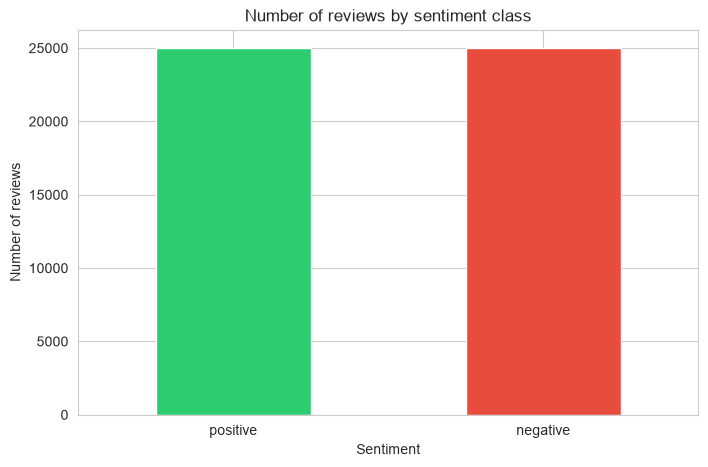

In [5]:
class_counts = df["sentiment"].value_counts()
print(class_counts.to_string())

class_counts.plot(kind="bar", color=["#2ecc71", "#e74c3c"])
plt.title("Number of reviews by sentiment class")
plt.xlabel("Sentiment")
plt.ylabel("Number of reviews")
plt.xticks(rotation=0)
plt.show()

## Review Length Distribution

Review length (number of characters and number of words) can indicate outliers and helps with later tuning of parameters in TF-IDF vectorization.


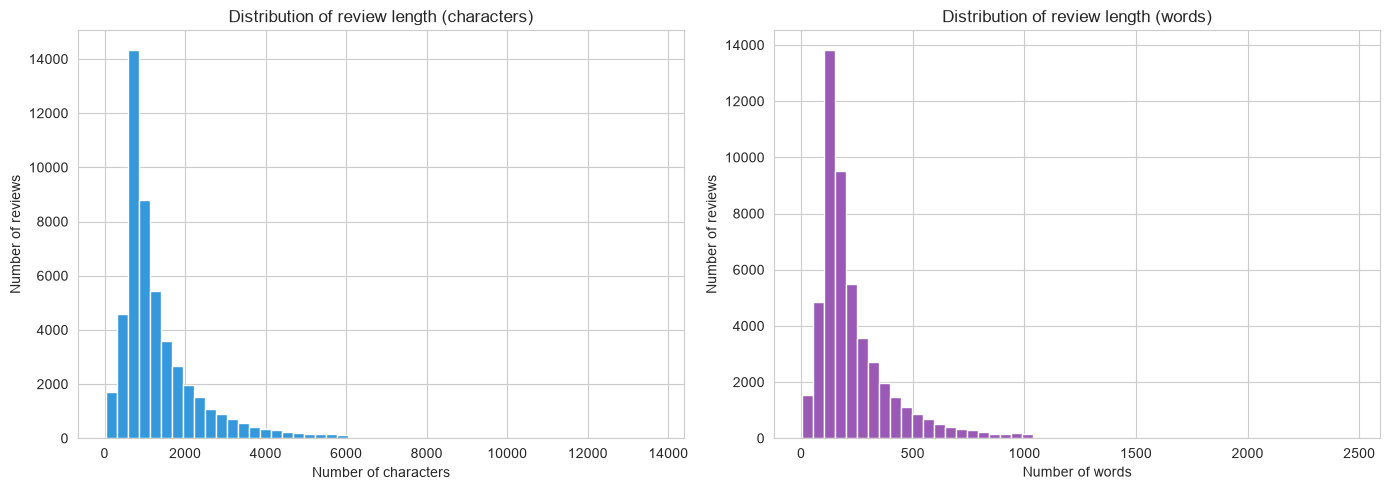

                    Number of characters  Number of words
Average                      1309.431040       231.156960
Standard deviation            989.728111       171.344087
Minimum                        32.000000         4.000000
Median                        970.000000       173.000000
Maximum                     13704.000000      2470.000000


In [6]:
df["char_length"] = df["review"].str.len()
df["word_count"] = df["review"].str.split().apply(len)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df["char_length"], bins=50, color="#3498db")
axes[0].set_title("Distribution of review length (characters)")
axes[0].set_xlabel("Number of characters")
axes[0].set_ylabel("Number of reviews")

axes[1].hist(df["word_count"], bins=50, color="#9b59b6")
axes[1].set_title("Distribution of review length (words)")
axes[1].set_xlabel("Number of words")
axes[1].set_ylabel("Number of reviews")

plt.tight_layout()
plt.show()


stats = pd.DataFrame({
    "Number of characters": [
        df["char_length"].mean(),
        df["char_length"].std(),
        df["char_length"].min(),
        df["char_length"].median(),
        df["char_length"].max()
    ],
    "Number of words": [
        df["word_count"].mean(),
        df["word_count"].std(),
        df["word_count"].min(),
        df["word_count"].median(),
        df["word_count"].max()
    ]
}, index=["Average", "Standard deviation", "Minimum", "Median", "Maximum"])

print(stats)

## Review Length by Class

We check whether there is a difference in the average length between positive and negative reviews (e.g. whether people tend to write longer when they are dissatisfied).


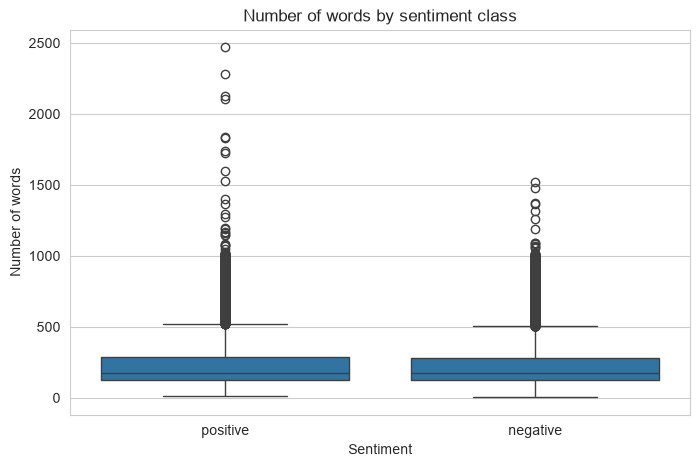

                       Positive     Negative
Average              232.849320   229.464600
Standard deviation   177.497046   164.947982
Minimum               10.000000     4.000000
Median               172.000000   174.000000
Maximum             2470.000000  1522.000000


In [7]:
sn.boxplot(data=df, x="sentiment", y="word_count")
plt.title("Number of words by sentiment class")
plt.xlabel("Sentiment")
plt.ylabel("Number of words")
plt.show()


stats_sentiment = pd.DataFrame({
    "Positive": [
        df[df["sentiment"] == "positive"]["word_count"].mean(),
        df[df["sentiment"] == "positive"]["word_count"].std(),
        df[df["sentiment"] == "positive"]["word_count"].min(),
        df[df["sentiment"] == "positive"]["word_count"].median(),
        df[df["sentiment"] == "positive"]["word_count"].max()
    ],
    "Negative": [
        df[df["sentiment"] == "negative"]["word_count"].mean(),
        df[df["sentiment"] == "negative"]["word_count"].std(),
        df[df["sentiment"] == "negative"]["word_count"].min(),
        df[df["sentiment"] == "negative"]["word_count"].median(),
        df[df["sentiment"] == "negative"]["word_count"].max()
    ]
}, index=["Average", "Standard deviation", "Minimum", "Median", "Maximum"])

print(stats_sentiment)

## Missing Values and Duplicates

Duplicates are particularly dangerous when performing a train/test split. If the same review appears in both the training and test sets, we get falsely optimistic results (data leakage).

Here we only identify them, while removal is performed in `2_preprocessing.ipynb`.


In [8]:
print("Number of missing values by column:")
for column, number in df[["review", "sentiment"]].isnull().sum().items():
    print(f"{column}: {number}")


num_duplicates = df.duplicated().sum()
print(f"\nNumber of duplicate rows: {num_duplicates}")

if num_duplicates > 0:
    display(df[df.duplicated(keep=False)].head())

Number of missing values by column:
review: 0
sentiment: 0

Number of duplicate rows: 418


,review,sentiment,char_length,word_count
42,"Of all the films I have seen, this one, The Ra...",negative,937,176
84,"We brought this film as a joke for a friend, a...",negative,402,75
140,"Before I begin, let me get something off my ch...",negative,2267,393
219,Ed Wood rides again. The fact that this movie ...,negative,892,168
245,I have seen this film at least 100 times and I...,positive,222,46


## Checking for HTML Artifacts

It is known that this dataset contains HTML tags (most commonly `<br />`) that are remnants from the IMDb website. If present, they must be removed because they introduce noise into tokenization.

Here we only identify them, while removal is performed in `2_preprocessing.ipynb`.


In [9]:
html_tag_count = df["review"].str.contains("<br", case=False, regex=False).sum()
print(f"Number of reviews containing HTML tags: {html_tag_count} out of {len(df)}")

example_with_html = df[df["review"].str.contains("<br", case=False, regex=False)]["review"].iloc[0]
print(f"\nExample review containing an HTML tag: {example_with_html[:300]}")

Number of reviews containing HTML tags: 29200 out of 50000

Example review containing an HTML tag: One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Tru


## Review of Specific Examples

One example each of a positive and negative review.


In [10]:
print("Example of POSITIVE review:")
print(df[df["sentiment"] == "positive"]["review"].iloc[0][:500])

print("\nExample of NEGATIVE review:")
print(df[df["sentiment"] == "negative"]["review"].iloc[0][:500])

Example of POSITIVE review:
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ

Example of NEGATIVE review:
Basically there's a family where a little boy (Jake) thinks there's a zombie in his closet & his parents are fighting all the time.<br /><br />This movie is slower than a soap opera... and suddenly, Jake decides to become Rambo and kill the zombie.<br /><br />OK, first of all when you're going to make a film you must Decide if its a thriller or a drama! As a drama the movie is watchable. Parents are divorcing & arguing like in real life. 

## Conclusions of the Exploratory Data Analysis (EDA)

- The dataset is perfectly balanced: 25,000 positive and 25,000 negative reviews.

- The distribution of review lengths is diverse, with a small number of extremely long reviews pulling the average above the median, while a typical review is considerably shorter.

- There is no significant difference in length between positive and negative reviews, as the average values and medians are very similar.

- There are no missing values.

- 418 duplicated rows were found - they will be removed during the preprocessing phase.

- 29,200 reviews containing HTML tags were found - they will be removed during the preprocessing phase.
